# 01 Using pretrained AI with cuvis-ai

Rebuilt from the course notebook `2026/using_pretrained_ai.ipynb` (https://github.com/LizaGenke/Chemometric-approaches-to-hyperspectral-processing, commit
`0d2c33e`) of the WUR course "AI for spectral and hyperspectral data processing"
(Liza Genke, Puneet Mishra). The course walks through four pretrained tools on one kiwi cube and
one pork data set: Segment Anything on a pseudo-RGB rendering, a YOLO detector on an RGB photo,
ImageNet ResNet-18 as a feature extractor, and PLS regression on fused spatial and spectral
features. Here every step is a cuvis-ai node, wired in the open, so the same graph runs from
`pipelines/01_pretrained_ai/*.yaml` and from this notebook.

One deviation from the course is stated up front: the segmenter is SAM3 (`cuvis-ai-sam3`)
instead of SAM v1, so the mask counts are reported next to the course's, not matched. The
detector is the course's own yolov8n, run through the nodes of `cuvis-ai-ultralytics`, with the
plugin's YOLO26 next to it for comparison.

In [1]:
# Colab bootstrap: installs cuvis-ai when this notebook runs on Colab, a no-op locally. The course
# plugin lives in a private repository until the course authors confirm the licence, so for now the
# notebook runs from a local checkout of this repository (`uv sync --all-extras`).
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    pass  # the next line only runs as a notebook magic, invisible to a plain Python parse
    %pip install -q cuvis-ai

In [2]:
# Provision the plugins this notebook needs. Their pins live in the plugin manifests packaged with
# cuvis-ai (cuvis_ai/configs/plugins) and in this repository's own manifest (plugins/): `provision`
# reads them off a pipeline that lists the same plugins, adds each manifest's extras and the data
# module's, and installs only what is missing. After a fresh install, restart the kernel
# (Kernel > Restart Kernel) and rerun from the top. This repository also pins the sam3 and
# ultralytics plugins as its `plugins` extra, so `uv sync --all-extras` has installed them already.
from importlib.resources import files
from pathlib import Path

from cuvis_ai_core.utils.provision import provision_environment, resolve_install_specs

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
CONFIGS = files("cuvis_ai") / "configs"
PLUGINS_DIRS = [REPO / "plugins", Path(str(CONFIGS / "plugins"))]
PROVISION = [  # (pipeline of this repository that lists the plugin(s), data module whose extras to add)
    ("01_pretrained_ai/kiwi_segment.yaml", "wur_course_npz"),
    ("01_pretrained_ai/yolo_rgb.yaml", None),
]
for pipeline_yaml, data_module in PROVISION:
    pipeline_path = REPO / "pipelines" / pipeline_yaml
    if IN_COLAB:  # no uv project on Colab: pip the resolved specs straight into this kernel
        specs = resolve_install_specs(pipeline_path, PLUGINS_DIRS, data_module)
        provision_environment(specs, notebook=True, apply=True)
    else:  # the same command you would run in a terminal from the repository root
        data_arg = f"--data-module {data_module}" if data_module else ""
        plugin_args = " ".join(f'--plugins-dir "{d}"' for d in PLUGINS_DIRS)
        !uv run --directory "{REPO}" provision --pipeline-path "{pipeline_path}" {plugin_args} {data_arg} --apply

2026-11-05 20:42:11.776 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'cuvis_ai_builtin' tag v0.22.1 → 5cdaec17 from https://github.com/cubert-hyperspectral/cuvis-ai.git
2026-11-05 20:42:12.402 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'sam3' tag v0.5.3 → ac79a576 from https://github.com/cubert-hyperspectral/cuvis-ai-sam3.git
2026-11-05 20:42:12.403 | INFO     | cuvis_ai_core.utils.provision:provision_environment:212 - All plugins already provisioned; nothing to install.


2026-11-05 20:42:13.728 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'cuvis_ai_builtin' tag v0.22.1 → 5cdaec17 from https://github.com/cubert-hyperspectral/cuvis-ai.git
2026-11-05 20:42:14.204 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'ultralytics' tag v0.1.5 → cfad358d from https://github.com/cubert-hyperspectral/cuvis-ai-ultralytics.git
2026-11-05 20:42:14.205 | INFO     | cuvis_ai_core.utils.provision:provision_environment:212 - All plugins already provisioned; nothing to install.


In [3]:
import numpy as np
import pandas as pd
import torch
from loguru import logger

logger.remove()
logger.add(sys.stderr, level="INFO")

DEVICE = (
    "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
)
DATA = REPO / "data" / "course"
# The stand-in written by tools/make_synthetic_course_data.py has the course's shapes and random
# content; with it the reproduction table reports our numbers without judging them.
SYNTHETIC = (REPO / "data" / "synthetic_course").exists()
sys.path.insert(0, str(REPO / "notebooks"))
import utils  # noqa: E402  (plotting and table helpers only)

print(f"device {DEVICE}, {'synthetic stand-in' if SYNTHETIC else 'course data'} under {DATA}")

device cuda, course data under D:\code-repos\cuvis-ai-wur-course-2026\wt-6884-notebook-rewrite\data\course


## Data

The course data (the Drive folder of the WUR course) is not a `PublicDatasets` entry: it is shared
for the course, and its licence for a public repository is pending. This notebook therefore deviates
from the standard provisioning block: `prepare-course-data` converts the Drive folder into the npz
frames read here (`README.md` lists the commands), and `tools/make_synthetic_course_data.py` writes a
random stand-in with the course's shapes so every cell runs before the data arrives.

In [4]:
for subset in ("kiwi", "pork_features"):
    if not (DATA / subset / "universe.csv").exists():
        raise FileNotFoundError(
            f"{DATA / subset} is missing: run prepare-course-data on the course folder, or "
            "`uv run python tools/make_synthetic_course_data.py` for the stand-in"
        )
pd.read_csv(DATA / "kiwi" / "universe.csv").head()

,source,index,materialized_path
0,kiwi_cube,0,frames/00000.npz


In [5]:
# The plugin manifests: this repository's course plugin, plus the packaged manifests of the plugins
# the pipelines list. The nodes below are constructed by import, so the registry is what a
# pipeline YAML or the restore-pipeline CLI resolves them through.
from cuvis_ai_core.utils.node_registry import NodeRegistry

registry = NodeRegistry()
registry.register_plugin(str(REPO / "plugins" / "cuvis_ai_wur_course.yaml"))
registry.register_plugin(str(CONFIGS / "plugins" / "sam3.yaml"))
registry.register_plugin(str(CONFIGS / "plugins" / "ultralytics.yaml"))
registry.list_plugins()

2026-11-05 20:42:20.896 | INFO     | cuvis_ai_core.utils.node_registry:register_plugins_installed:573 - Loaded preinstalled plugin 'cuvis_ai_wur_course' with 22 nodes


2026-11-05 20:42:20.896 | INFO     | cuvis_ai_core.utils.node_registry:register_plugin:408 - Registered plugin 'cuvis_ai_wur_course' from D:\code-repos\cuvis-ai-wur-course-2026\wt-6884-notebook-rewrite\plugins\cuvis_ai_wur_course.yaml


D:\code-repos\cuvis-ai-wur-course-2026\wt-6884-notebook-rewrite\.venv\Lib\site-packages\sam3\model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


D:\code-repos\cuvis-ai-wur-course-2026\wt-6884-notebook-rewrite\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
2026-11-05 20:42:21.223 | INFO     | cuvis_ai_core.utils.node_registry:register_plugins_installed:573 - Loaded preinstalled plugin 'sam3' with 6 nodes


2026-11-05 20:42:21.224 | INFO     | cuvis_ai_core.utils.node_registry:register_plugin:408 - Registered plugin 'sam3' from D:\code-repos\cuvis-ai-wur-course-2026\wt-6884-notebook-rewrite\.venv\Lib\site-packages\cuvis_ai\configs\plugins\sam3.yaml


2026-11-05 20:42:21.231 | INFO     | cuvis_ai_core.utils.node_registry:register_plugins_installed:573 - Loaded preinstalled plugin 'ultralytics' with 3 nodes


2026-11-05 20:42:21.232 | INFO     | cuvis_ai_core.utils.node_registry:register_plugin:408 - Registered plugin 'ultralytics' from D:\code-repos\cuvis-ai-wur-course-2026\wt-6884-notebook-rewrite\.venv\Lib\site-packages\cuvis_ai\configs\plugins\ultralytics.yaml


['cuvis_ai_wur_course', 'sam3', 'ultralytics']

## 1. One kiwi out of a cube: SAM3, a size filter and a spectral-angle filter

The course renders the cube as a pseudo-RGB image (575, 535 and 445 nm), lets Segment Anything
propose every region, and then keeps the kiwis in two alternative ways: a bounding-box size filter
(height 50 to 120 px, width 150 to 210 px) and a spectral filter that compares each region's mean
spectrum with a saved kiwi reference spectrum by spectral angle (cutoff 0.035 rad). One kiwi of the
spectrally filtered set is cropped to a 256 x 256 canvas and embedded with ResNet-18.

Three small pipelines carry this, one per stage, so each diagram stays readable: `kiwi_segment`
renders the pseudo-RGB and runs SAM3 once, `kiwi_filters` runs the size filter and the spectral
filter side by side on SAM3's mask, and `kiwi_crop_features` crops and embeds one kiwi of the
spectral filter's output. SAM3 is the expensive step, so it runs only in the first stage; the
later stages take its mask and object ids as plain batch values, the hand-off a reader sees built
in the cell before each `pipeline.forward(...)` call.

In [6]:
from cuvis_ai_core.data.splits_io import load_splits

from cuvis_ai_wur_course.data.course_npz import CourseNpzDataModule

kiwi_data = CourseNpzDataModule(
    universe_csv=str(DATA / "kiwi" / "universe.csv"),
    splits=load_splits(DATA / "kiwi" / "splits.json"),
    batch_size=1,
)
kiwi_data.setup(stage="predict")
kiwi_batch = next(iter(kiwi_data.predict_dataloader()))
{key: tuple(value.shape) for key, value in kiwi_batch.items() if hasattr(value, "shape")}

{'cube': (1, 930, 1024, 224),
 'mask': (1, 930, 1024),
 'wavelengths': (1, 224),
 'mesu_index': (1,),
 'frame_id': (1,)}

In [7]:
from cuvis_ai.node.channel_selector import FixedWavelengthSelector
from cuvis_ai_core.pipeline.pipeline import CuvisPipeline
from cuvis_ai_sam3.node import SAM3SegmentEverything

from cuvis_ai_wur_course.node.source import CourseFrame

PSEUDO_RGB_NM = (575.0, 535.0, 445.0)

frame = CourseFrame(name="frame", keys=("wavelengths",))
pseudo_rgb = FixedWavelengthSelector(name="pseudo_rgb", target_wavelengths=PSEUDO_RGB_NM)
sam3 = SAM3SegmentEverything(name="sam3")

kiwi_segment = CuvisPipeline("kiwi_segment")
kiwi_segment.connect(
    (frame.outputs.cube, pseudo_rgb.inputs.cube),
    (frame.outputs.wavelengths, pseudo_rgb.inputs.wavelengths),
    (pseudo_rgb.outputs.rgb_image, sam3.inputs.rgb_image),
)
utils.show_pipeline(kiwi_segment)

2026-11-05 20:42:31.633 | INFO     | cuvis_ai_sam3.shared_backbone:_acquire_backbone:431 - built shared ViT backbone (vit1024d32_1008-instneck, cuda:0)


2026-11-05 20:42:32.281 | INFO     | cuvis_ai_sam3.node._sam3_image_base:_ensure_model:111 - SAM3SegmentEverything image model loaded (device=cuda:0)


Predict [kiwi_segment]:   0%|          | 0/1 [00:00<?, ?batch/s]

D:\code-repos\cuvis-ai-wur-course-2026\wt-6884-notebook-rewrite\.venv\Lib\site-packages\triton\knobs.py:524: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


SAM3 objects: 48


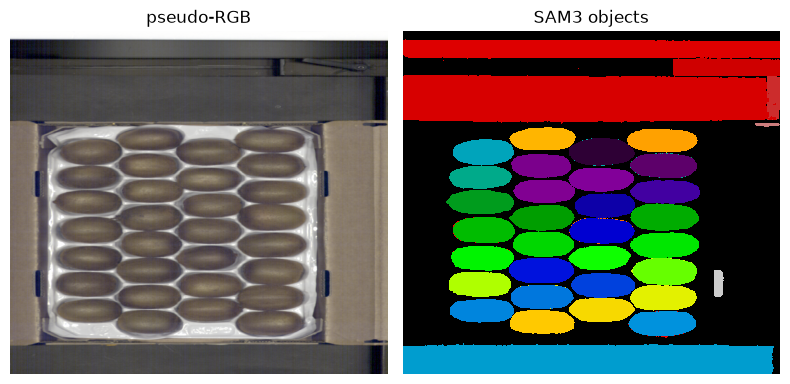

In [8]:
from cuvis_ai_core.training import Predictor
from cuvis_ai_schemas.enums import ExecutionStage

kiwi_segment.to(DEVICE)
SEGMENT_PORTS = {"cube", "wavelengths", "rgb_image", "mask", "object_ids"}
kiwi_segment_out = Predictor(kiwi_segment, kiwi_data).predict(
    stage=ExecutionStage.INFERENCE, collect_outputs=True, collect_ports=SEGMENT_PORTS
)[0]
print(f"SAM3 objects: {int(kiwi_segment_out[('sam3', 'mask')].max())}")
utils.show_images(
    [
        ("pseudo-RGB", kiwi_segment_out[("pseudo_rgb", "rgb_image")][0]),
        ("SAM3 objects", kiwi_segment_out[("sam3", "mask")][0]),
    ]
)

In [9]:
from cuvis_ai.node.deciders.binary_decider import ScoreThreshold
from cuvis_ai.node.metrics import DistinctLabelCount
from cuvis_ai.node.numpy_file import NpyReader
from cuvis_ai.node.spectral_angle_mapper import SpectralAngleMapper
from cuvis_ai.node.spectral_extractor import SignaturesToReferences, SpectralSignatureExtractor

from cuvis_ai_wur_course.node.kiwi import LabelBBoxFilter, LabelKeep

size_filter = LabelBBoxFilter(
    name="size_filter", min_height=50, max_height=120, min_width=150, max_width=210
)
count_size_filter = DistinctLabelCount(name="count_size_filter")
object_spectra = SpectralSignatureExtractor(
    name="object_spectra", trim_fraction=0.0, min_mask_pixels=1
)
object_references = SignaturesToReferences(name="object_references")
kiwi_reference = NpyReader(
    name="kiwi_reference", file_path=str(DATA / "kiwi" / "kiwi_reference.npy")
)
kiwi_angle = SpectralAngleMapper(name="kiwi_angle")
kiwi_decision = ScoreThreshold(name="kiwi_decision", threshold=0.035, keep="below")
spectral_filter = LabelKeep(name="spectral_filter")
count_spectral_filter = DistinctLabelCount(name="count_spectral_filter")

kiwi_filters = CuvisPipeline("kiwi_filters")
kiwi_filters.connect(
    # branch A: the size filter on the batch mask
    (size_filter.outputs.mask, count_size_filter.inputs.mask),
    # branch B: the spectral-angle filter against the saved kiwi spectrum; object_spectra and
    # spectral_filter read cube, wavelengths, mask and object_ids from the batch (unconnected
    # input ports of those names, filled by kiwi_segment's hand-off below)
    (object_spectra.outputs.signatures, object_references.inputs.signatures),
    (object_references.outputs.spectral_signature, kiwi_angle.inputs.cube),
    (kiwi_reference.outputs.data, kiwi_angle.inputs.spectral_signature),
    (kiwi_angle.outputs.best_scores, kiwi_decision.inputs.scores),
    (kiwi_decision.outputs.decisions, spectral_filter.inputs.decisions),
    (spectral_filter.outputs.mask, count_spectral_filter.inputs.mask),
)
utils.show_pipeline(kiwi_filters)

after the size filter: 38, after the spectral filter: 28


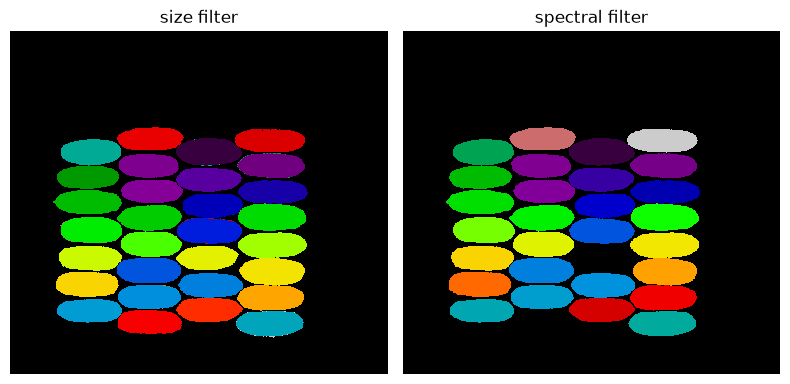

In [10]:
# The hand-off from kiwi_segment: the pipeline feeds batch keys into ports by name, so every
# unconnected input port named cube, wavelengths, mask or object_ids in kiwi_filters receives
# the matching value here. The Predictor hands its collected outputs back on the CPU; the
# tensors go to DEVICE with the stage.
hand_off = {
    "cube": kiwi_segment_out[("frame", "cube")].to(DEVICE),
    "wavelengths": kiwi_segment_out[("frame", "wavelengths")],
    "mask": kiwi_segment_out[("sam3", "mask")].to(DEVICE),
    "object_ids": kiwi_segment_out[("sam3", "object_ids")].to(DEVICE),
}
kiwi_filters.to(DEVICE)
kiwi_filters_out = kiwi_filters.forward(batch=hand_off, stage=ExecutionStage.INFERENCE)
masks_after_size = int(kiwi_filters_out[("count_size_filter", "count")][0])
masks_after_spectrum = int(kiwi_filters_out[("count_spectral_filter", "count")][0])
print(
    f"after the size filter: {masks_after_size}, after the spectral filter: {masks_after_spectrum}"
)
utils.show_images(
    [
        ("size filter", kiwi_filters_out[("size_filter", "mask")][0]),
        ("spectral filter", kiwi_filters_out[("spectral_filter", "mask")][0]),
    ]
)

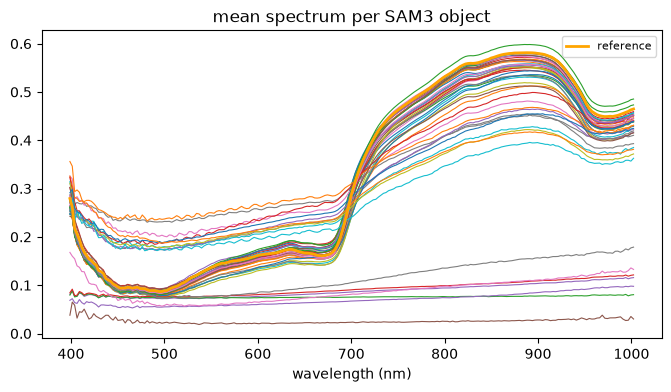

,object,angle_rad,kept
0,1,0.019174,1
1,2,0.017984,1
2,3,0.032678,1
3,4,0.025340,1
4,5,0.024150,1
5,6,0.016125,1
6,7,0.022170,1
7,8,0.291546,0
8,9,0.011415,1
9,10,0.022461,1


In [11]:
reference_spectrum = np.load(DATA / "kiwi" / "kiwi_reference.npy").ravel()
signatures = kiwi_filters_out[("object_spectra", "signatures")][0].cpu()
angles = kiwi_filters_out[("kiwi_angle", "best_scores")].flatten().cpu()
utils.plot_spectra(
    kiwi_batch["wavelengths"][0],
    signatures,
    "mean spectrum per SAM3 object",
    reference=reference_spectrum,
)
pd.DataFrame(
    {
        "object": range(1, len(angles) + 1),
        "angle_rad": angles.numpy(),
        "kept": kiwi_filters_out[("spectral_filter", "kept")].flatten().cpu().numpy(),
    }
)

In [12]:
from cuvis_ai_wur_course.node.features import ResNet18Features
from cuvis_ai_wur_course.node.kiwi import LabelCropPad

kiwi_crop = LabelCropPad(name="kiwi_crop", canvas_size=256, label_selection="first")
crop_rgb = FixedWavelengthSelector(name="crop_rgb", target_wavelengths=PSEUDO_RGB_NM)
features = ResNet18Features(name="features", weights="imagenet")

kiwi_crop_features = CuvisPipeline("kiwi_crop_features")
kiwi_crop_features.connect(
    (kiwi_crop.outputs.crop, crop_rgb.inputs.cube),
    (crop_rgb.outputs.rgb_image, features.inputs.image),
)
utils.show_pipeline(kiwi_crop_features)

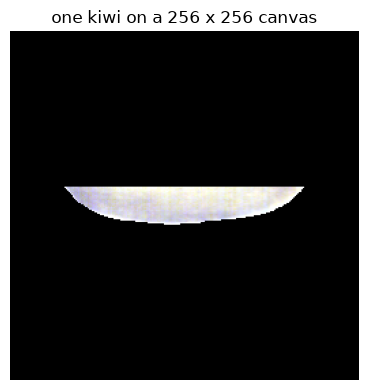

ResNet-18 features of the crop: (512,) norm 21.189


In [13]:
# The hand-off: cube and wavelengths from kiwi_segment's frame, mask from the spectral filter
# (kiwi_crop reads cube and mask; crop_rgb needs wavelengths to render the crop as pseudo-RGB).
hand_off = {
    "cube": kiwi_segment_out[("frame", "cube")].to(DEVICE),
    "wavelengths": kiwi_segment_out[("frame", "wavelengths")],
    "mask": kiwi_filters_out[("spectral_filter", "mask")],
}
kiwi_crop_features.to(DEVICE)
kiwi_crop_out = kiwi_crop_features.forward(batch=hand_off, stage=ExecutionStage.INFERENCE)
crop_features = kiwi_crop_out[("features", "features")][0]
utils.show_images([("one kiwi on a 256 x 256 canvas", kiwi_crop_out[("crop_rgb", "rgb_image")][0])])
print(
    "ResNet-18 features of the crop:",
    tuple(crop_features.shape),
    "norm",
    round(float(crop_features.norm()), 3),
)

## 2. A detector on an RGB photo: yolov8n, and YOLO26 next to it

The course runs yolov8n on two photos: the RGB rendering of the kiwi tray (`1A_rgb.png`, two
ovens) and `carrots.jpg` (a person and eleven carrots). The ultralytics plugin splits a detector
into three nodes: the letterbox preprocessing (here with `imgsz=640`, the input size an
ultralytics predict call uses by default), the detector on the raw tensor, and the postprocessing
that turns the raw predictions into boxes, class ids and confidences. The detector node loads any
ultralytics weight file, so the same four-node graph runs yolov8n for the course's numbers and
then YOLO26, the plugin's current default, whose labels are reported for comparison. The photos
are read from `data/course/images/` when present; the stand-in for the tray is the kiwi rendering
from above.

In [14]:
from cuvis_ai.node.video import VideoFrameNode
from cuvis_ai_ultralytics.node import YOLO26Detection, YOLOPostprocess, YOLOPreprocess
from PIL import Image


def read_photo(path):
    return torch.from_numpy(np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0)[
        None
    ]


photos = {}
for photo_name, file_name in (("kiwi tray", "1A_rgb.png"), ("carrots", "carrots.jpg")):
    photo_path = DATA / "images" / file_name
    if photo_path.exists():
        photos[photo_name] = read_photo(photo_path)
if not photos:
    photos["kiwi tray"] = kiwi_segment_out[("pseudo_rgb", "rgb_image")]
rgb = photos["kiwi tray"]

yolo_pipelines = {}
for weights in ("yolov8n.pt", "yolo26n.pt"):
    rgb_frame = VideoFrameNode(name="frame")
    preprocess = YOLOPreprocess(name="preprocess", imgsz=640)
    detector = YOLO26Detection(name="detector", model_path=weights)
    postprocess = YOLOPostprocess(name="postprocess", confidence_threshold=0.25)
    yolo_pipelines[weights] = CuvisPipeline("yolo_rgb_" + weights.removesuffix(".pt"))
    yolo_pipelines[weights].connect(
        (rgb_frame.outputs.rgb_image, preprocess.inputs.rgb_image),
        (preprocess.outputs.preprocessed, detector.inputs.preprocessed),
        (detector.outputs.raw_preds, postprocess.inputs.raw_preds),
        (preprocess.outputs.model_input_hw, postprocess.inputs.model_input_hw),
        (preprocess.outputs.orig_hw, postprocess.inputs.orig_hw),
    )
utils.show_pipeline(yolo_pipelines["yolov8n.pt"])

2026-11-05 20:42:52.192 | INFO     | cuvis_ai_ultralytics.node.yolo26_detection:__init__:72 - Loading YOLO model: yolov8n.pt


2026-11-05 20:42:53.067 | INFO     | cuvis_ai_ultralytics.node.yolo26_detection:__init__:94 - YOLO model loaded (stride=32)


2026-11-05 20:42:53.068 | INFO     | cuvis_ai_ultralytics.node.yolo26_detection:__init__:72 - Loading YOLO model: yolo26n.pt


2026-11-05 20:42:53.626 | INFO     | cuvis_ai_ultralytics.node.yolo26_detection:__init__:94 - YOLO model loaded (stride=32)


In [15]:
from cuvis_ai_schemas.execution import Context
from ultralytics import YOLO

detections = {}
for weights, pipeline in yolo_pipelines.items():
    pipeline.to(DEVICE)
    class_names = YOLO(weights).names
    for photo_name, photo in photos.items():
        with torch.no_grad():
            yolo_out = pipeline.forward(
                batch={
                    "rgb_image": photo.to(DEVICE),
                    "frame_id": torch.zeros(1, dtype=torch.int64, device=DEVICE),
                },
                context=Context(
                    stage=ExecutionStage.INFERENCE, epoch=0, batch_idx=0, global_step=0
                ),
            )
        boxes = yolo_out[("postprocess", "bboxes")][0].cpu()
        ids = yolo_out[("postprocess", "category_ids")][0].cpu()
        confidences = yolo_out[("postprocess", "confidences")][0].cpu()
        detections[(weights, photo_name)] = pd.DataFrame(
            {
                "weights": weights,
                "photo": photo_name,
                "label": [class_names[int(i)] for i in ids],
                "confidence": confidences.numpy().round(3),
                "box_xyxy": [b.numpy().round(1).tolist() for b in boxes],
            }
        )


def label_counts(table):
    counts = table["label"].value_counts()  # most frequent label first
    return (
        ", ".join(f"{n} {label}" for label, n in counts.items()) if len(counts) else "no detection"
    )


yolo_labels = {
    weights: "; ".join(label_counts(detections[(weights, photo_name)]) for photo_name in photos)
    for weights in yolo_pipelines
}
for weights, labels in yolo_labels.items():
    print(f"{weights}: {labels}")
pd.concat(detections.values(), ignore_index=True)

yolov8n.pt: 2 oven; 11 carrot, 1 person
yolo26n.pt: 3 donut; 8 hot dog, 1 carrot


,weights,photo,label,confidence,box_xyxy
0,yolov8n.pt,kiwi tray,oven,0.544,"[50.900002, 248.399994, 874.299988, 898.0]"
1,yolov8n.pt,kiwi tray,oven,0.337,"[22.200001, 52.799999, 1021.700012, 930.0]"
2,yolov8n.pt,carrots,carrot,0.699,"[517.5, 242.699997, 601.700012, 378.700012]"
3,yolov8n.pt,carrots,carrot,0.687,"[384.799988, 245.0, 415.200012, 398.100006]"
4,yolov8n.pt,carrots,carrot,0.684,"[500.899994, 275.700012, 544.799988, 476.100006]"
5,yolov8n.pt,carrots,person,0.659,"[0.6, 1.0, 99.599998, 237.0]"
6,yolov8n.pt,carrots,carrot,0.594,"[245.699997, 236.0, 283.899994, 382.700012]"
7,yolov8n.pt,carrots,carrot,0.478,"[304.5, 223.300003, 343.100006, 398.600006]"
8,yolov8n.pt,carrots,carrot,0.460,"[354.0, 223.199997, 395.100006, 399.399994]"
9,yolov8n.pt,carrots,carrot,0.427,"[461.200012, 199.399994, 520.799988, 379.600006]"


## 3. ResNet-18 as a feature extractor

ImageNet ResNet-18 without its classifier turns any RGB image into 512 numbers. The course
embeds its photos this way and uses the same kind of vector, computed on pork belly photos, as
the "spatial" block of the fusion model below.

In [16]:
photo_frame = VideoFrameNode(name="frame")
photo_features = ResNet18Features(name="features", weights="imagenet")
features_pipeline = CuvisPipeline("resnet18_features")
features_pipeline.connect((photo_frame.outputs.rgb_image, photo_features.inputs.image))
utils.show_pipeline(features_pipeline)

In [17]:
features_pipeline.to(DEVICE)
with torch.no_grad():
    photo_vector = features_pipeline.forward(
        batch={
            "rgb_image": rgb.to(DEVICE),
            "frame_id": torch.zeros(1, dtype=torch.int64, device=DEVICE),
        },
        context=Context(stage=ExecutionStage.INFERENCE, epoch=0, batch_idx=0, global_step=0),
    )[("features", "features")][0].cpu()
cosine = float(torch.nn.functional.cosine_similarity(photo_vector, crop_features.cpu(), dim=0))
print(
    f"photo features {tuple(photo_vector.shape)}, cosine similarity with the kiwi crop: {cosine:.3f}"
)

photo features (512,), cosine similarity with the kiwi crop: 0.998


## 4. Fat from fused features: three PLS models and an average

`spatial_spectra_pig.mat` holds, per pork belly, 512 ResNet-18 features of the photo and 300
spectral features, with the lab reference. The course standardises every feature, fits PLS on the
spatial block, on the spectral block and on both stacked, choosing the number of latent variables
by five-fold cross-validation (1 to 20), and averages the spatial and spectral predictions
("high-level fusion"). `prepare-course-data pork-features` wrote the bellies as 1 x 1 x 812 frames
in the course's train/test order with the course's fold ids, so the PLS nodes select their
component count exactly as `cross_val_predict` did.

In [18]:
from cuvis_ai.node.pretreatments.standardize import Standardize

from cuvis_ai_wur_course.node.fusion import ChannelSlice, PredictionMean
from cuvis_ai_wur_course.node.metrics import RegressionMetrics
from cuvis_ai_wur_course.node.regression import PLSRegression

SPATIAL, SPECTRAL, MAX_COMPONENTS = 512, 300, 20

pork_frame = CourseFrame(name="frame", keys=("wavelengths", "target", "fold"))
standardize = Standardize(name="standardize", axis="channel")
spatial_block = ChannelSlice(name="spatial_block", start=0, stop=SPATIAL)
spectral_block = ChannelSlice(name="spectral_block", start=SPATIAL, stop=SPATIAL + SPECTRAL)
pls_spatial = PLSRegression(
    name="pls_spatial",
    input_channels=SPATIAL,
    max_components=MAX_COMPONENTS,
    holdout_folds="each",
    refit_on_holdout=True,
)
pls_spectral = PLSRegression(
    name="pls_spectral",
    input_channels=SPECTRAL,
    max_components=MAX_COMPONENTS,
    holdout_folds="each",
    refit_on_holdout=True,
)
pls_stacked = PLSRegression(
    name="pls_stacked",
    input_channels=SPATIAL + SPECTRAL,
    max_components=MAX_COMPONENTS,
    holdout_folds="each",
    refit_on_holdout=True,
)
fusion = PredictionMean(name="fusion")
metrics_spatial, metrics_spectral = (
    RegressionMetrics(name="metrics_spatial"),
    RegressionMetrics(name="metrics_spectral"),
)
metrics_stacked, metrics_fusion = (
    RegressionMetrics(name="metrics_stacked"),
    RegressionMetrics(name="metrics_fusion"),
)

pork_pipeline = CuvisPipeline("pork_pls_fusion")
pork_pipeline.connect(
    (pork_frame.outputs.cube, standardize.inputs.cube),
    (standardize.outputs.cube, spatial_block.inputs.cube),
    (standardize.outputs.cube, spectral_block.inputs.cube),
    # connected on purpose: an unconnected optional wavelengths port would be filled from the batch
    (pork_frame.outputs.wavelengths, spatial_block.inputs.wavelengths),
    (pork_frame.outputs.wavelengths, spectral_block.inputs.wavelengths),
    (spatial_block.outputs.cube, pls_spatial.inputs.cube),
    (spectral_block.outputs.cube, pls_spectral.inputs.cube),
    (standardize.outputs.cube, pls_stacked.inputs.cube),
)
for pls, metrics in (
    (pls_spatial, metrics_spatial),
    (pls_spectral, metrics_spectral),
    (pls_stacked, metrics_stacked),
):
    pork_pipeline.connect(
        (pork_frame.outputs.target, pls.inputs.target),
        (pork_frame.outputs.fold, pls.inputs.fold),
        (pls.outputs.prediction, metrics.inputs.prediction),
        (pork_frame.outputs.target, metrics.inputs.target),
    )
pork_pipeline.connect(
    (pls_spatial.outputs.prediction, fusion.inputs.prediction),
    (pls_spectral.outputs.prediction, fusion.inputs.prediction),
    (fusion.outputs.prediction, metrics_fusion.inputs.prediction),
    (pork_frame.outputs.target, metrics_fusion.inputs.target),
)
utils.show_pipeline(pork_pipeline)

2026-11-05 20:42:57.670 | INFO     | cuvis_ai_core.training.trainers:fit:707 - Training 4 statistical nodes...


2026-11-05 20:42:57.671 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting standardize


2026-11-05 20:42:58.105 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted standardize


2026-11-05 20:42:58.106 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting pls_stacked


2026-11-05 20:42:58.189 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted pls_stacked


2026-11-05 20:42:58.190 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting pls_spatial


2026-11-05 20:42:58.264 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted pls_spatial


2026-11-05 20:42:58.265 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting pls_spectral


2026-11-05 20:42:58.335 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted pls_spectral


pls_spatial: 5 latent variables
pls_spectral: 17 latent variables
pls_stacked: 4 latent variables


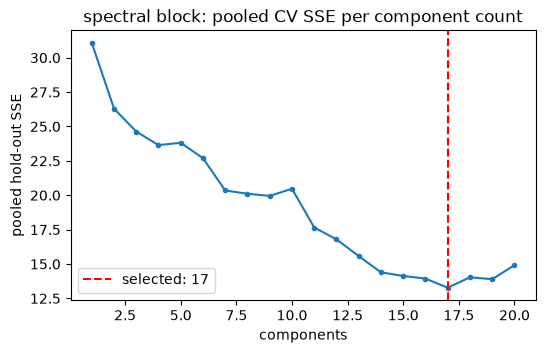

In [19]:
from cuvis_ai_core.training import StatisticalTrainer

pork_data = CourseNpzDataModule(
    universe_csv=str(DATA / "pork_features" / "universe.csv"),
    splits=load_splits(DATA / "pork_features" / "splits.json"),
    batch_size=16,
)
pork_trainer = StatisticalTrainer(
    pipeline=pork_pipeline,
    datamodule=pork_data,
    metric_nodes=[metrics_spatial, metrics_spectral, metrics_stacked, metrics_fusion],
)
pork_trainer.fit()
for pls in (pls_spatial, pls_spectral, pls_stacked):
    print(f"{pls.name}: {int(pls.n_selected)} latent variables")
utils.plot_component_selection(
    pls_spectral.cv_sse,
    int(pls_spectral.n_selected),
    "spectral block: pooled CV SSE per component count",
)

In [20]:
pork_test = pork_trainer.test()
pork_metrics = {
    name: node.compute()
    for name, node in (
        ("spatial", metrics_spatial),
        ("spectral", metrics_spectral),
        ("stacked", metrics_stacked),
        ("average fusion", metrics_fusion),
    )
}
pd.DataFrame(pork_metrics).T.round(3)

,rmse,r2,mae
spatial,0.447,0.610,0.326
spectral,0.321,0.799,0.261
stacked,0.402,0.685,0.307
average fusion,0.333,0.783,0.260


Predict [pork_pls_fusion]:   0%|          | 0/3 [00:00<?, ?batch/s]

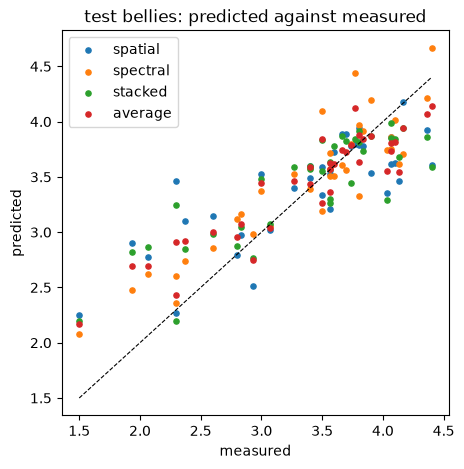

In [21]:
from cuvis_ai_schemas.training.data import DataSplitConfig

pork_test_data = CourseNpzDataModule(
    universe_csv=str(DATA / "pork_features" / "universe.csv"),
    splits=DataSplitConfig(predict=load_splits(DATA / "pork_features" / "splits.json").test),
    batch_size=16,
)
pork_out = Predictor(pork_pipeline, pork_test_data).predict(
    stage=ExecutionStage.TEST, collect_outputs=True, collect_ports={"prediction", "target"}
)
target = torch.cat([o[("frame", "target")] for o in pork_out])
predictions = {
    name: torch.cat([o[(node, "prediction")] for o in pork_out]).mean(dim=(1, 2))
    for name, node in (
        ("spatial", "pls_spatial"),
        ("spectral", "pls_spectral"),
        ("stacked", "pls_stacked"),
        ("average", "fusion"),
    )
}
utils.plot_predictions(target, predictions, "test bellies: predicted against measured")

## Reproduction

The course numbers are the printed outputs of the course notebook at the commit named at the top.
Mask counts are reported, not matched (SAM3 stands in for SAM v1). The yolov8n row compares the
label counts per photo, most frequent label first, with the course's; the YOLO26 row is reported.
The stacking-fusion row (course 0.308 / 0.815) is deferred.

In [22]:
rows = [
    ("kiwi masks after the size filter", 30, masks_after_size, None),
    ("kiwi masks after the spectral filter", 30, masks_after_spectrum, None),
    (
        "YOLO labels, yolov8n (the course's model)",
        "2 oven; 11 carrot, 1 person",
        yolo_labels["yolov8n.pt"],
        0,
    ),
    (
        "YOLO labels, YOLO26 (the plugin's default)",
        "2 oven; 11 carrot, 1 person",
        yolo_labels["yolo26n.pt"],
        None,
    ),
    ("PLS spatial, latent variables", 5, int(pls_spatial.n_selected), 0),
    ("PLS spatial RMSE", 0.447, round(pork_metrics["spatial"]["rmse"], 3), 1e-3),
    ("PLS spatial R2", 0.610, round(pork_metrics["spatial"]["r2"], 3), 1e-3),
    ("PLS spectral, latent variables", 17, int(pls_spectral.n_selected), 0),
    ("PLS spectral RMSE", 0.321, round(pork_metrics["spectral"]["rmse"], 3), 1e-3),
    ("PLS spectral R2", 0.799, round(pork_metrics["spectral"]["r2"], 3), 1e-3),
    ("PLS stacked RMSE", 0.402, round(pork_metrics["stacked"]["rmse"], 3), 1e-3),
    ("PLS stacked R2", 0.685, round(pork_metrics["stacked"]["r2"], 3), 1e-3),
    ("average fusion RMSE", 0.333, round(pork_metrics["average fusion"]["rmse"], 3), 1e-3),
    ("average fusion R2", 0.783, round(pork_metrics["average fusion"]["r2"], 3), 1e-3),
]
utils.reproduction_table(rows, synthetic=SYNTHETIC)

,row,course,ours,tolerance,status
0,kiwi masks after the size filter,30,38,NaN,reported
1,kiwi masks after the spectral filter,30,28,NaN,reported
2,"YOLO labels, yolov8n (the course's model)","2 oven; 11 carrot, 1 person","2 oven; 11 carrot, 1 person",0.000,pass
3,"YOLO labels, YOLO26 (the plugin's default)","2 oven; 11 carrot, 1 person","3 donut; 8 hot dog, 1 carrot",NaN,reported
4,"PLS spatial, latent variables",5,5,0.000,pass
5,PLS spatial RMSE,0.447,0.447,0.001,pass
6,PLS spatial R2,0.61,0.61,0.001,pass
7,"PLS spectral, latent variables",17,17,0.000,pass
8,PLS spectral RMSE,0.321,0.321,0.001,pass
9,PLS spectral R2,0.799,0.799,0.001,pass
